Set up the VIIRS NDVI and EVI data to be processed using Google Earth Engine

Author: Tayler LaSharr;
Date: 10 Sept 2023


In [6]:
## first we will read in necessary python libraries and intialize the GEE module
## you will have to authenticate GEE on your machine to use this code

import ee
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import geopandas as gpd
import matplotlib.pyplot as plt
import json

## if you need to authenticate GEE use this code
## ee.Authenticate('your-GEE-project')

## initialize the Earth Engine module
ee.Initialize()

c:\Users\tlasharr\AppData\Local\Programs\Python\Python312\Lib\site-packages\ee\deprecation.py:207: DeprecationWarning: 

Attention required for MODIS/006/MOD10A1! You are using a deprecated asset.
To ensure continued functionality, please update it.
Learn more: https://developers.google.com/earth-engine/datasets/catalog/MODIS_006_MOD10A1

  warnings.warn(warning, category=DeprecationWarning)


Projection of the cooridor shapefile: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}


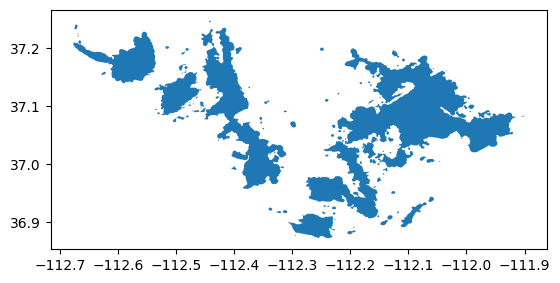

In [7]:
## load in a shapefile or area of interest
## this is an assest that is already loaded into GEE

md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/UT_Paunsaugunt')
# md_cooridor = ee.FeatureCollection('projects/ee-tlasharr/assets/WY_Sublette')

## load in the VIIRS data and the MODIS snow data
viirs_ndvi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('NDVI')

viirs_evi = ee.ImageCollection('NASA/VIIRS/002/VNP13A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('EVI')

modis_snow = ee.ImageCollection('MODIS/006/MOD10A1') \
                .filterDate('2018-01-01', '2023-12-31') \
                .select('NDSI_Snow_Cover')

## first see the projection of the shapefile
coordidor_projection = md_cooridor.first().geometry().projection()
print('Projection of the cooridor shapefile:', coordidor_projection.getInfo())

## now we can reproject the shapefile
viirs_projection = viirs_ndvi.first().projection() ## this is the projection of the first image of the modis ndvi data
target_crs = viirs_projection.crs() ## this is the crs from the modis.projection object
target_crs_scale = viirs_projection.nominalScale() ## this is the scale (confused on what this is need to figure this out)

## this is a function to reproject it
def reproject_feature(feature):
    return feature.setGeometry(feature.geometry().transform(target_crs, target_crs_scale))

## this is running the function, so now "reprojected_roi" is the new object we care about
reprojected_roi = md_cooridor.map(reproject_feature)

## then plot it
geojson = md_cooridor.getInfo()
gdf = gpd.GeoDataFrame.from_features(geojson['features'])
gdf.plot()
plt.show()               

In [8]:
## next, we can clip the data to the cooridor that we are working with

## clip VIIRS NDVI and EVI datasets
clipped_viirs_ndvi = viirs_ndvi.map(lambda image: image.clip(reprojected_roi))
clipped_viirs_evi = viirs_evi.map(lambda image: image.clip(reprojected_roi))


Everything above this is just getting the raw data clipped and ready to go for processing. Next, we are going to actually process the data. We have altered the methods slightly from Bischof's 2012 methods to help us fit curves in arid environments.

We are going to try to develop some methods that can be used for all of the data, so that we don't have to run seperate methods for temperate and arid landscapes.

Step 1. Deal with snow.

In [9]:
## VIIRS does not have a 'pixel quality' band, so I did not do the first step of replacing
## bands with a value of 0 as 'no data' which is what Bischof did.

## So the first thing we have to do is fix snow in the NDVI data.
## For now, I am going to shift slightly from the Bischof methods because I don't want to
## overestimate green-up for desert systems

## to do this, first we will define a function to mask snow cover, this is a step to help us
## understand how snow plays into the curves which might be especially important for 
## desert systems, right now I set it to mask cells with more than 20% snow cover.

def apply_snow_mask(image, snow_image):
    snow_mask = ee.Algorithms.If(
        snow_image,
        snow_image.lte(20),  ## if the snow cover is less than or equal to 20%
        ee.Image(1)          ## default mask (all values included if no corresponding snow image)
    )
    return image.updateMask(snow_mask)

## now mask the cells with less than 20% snow cover
viirs_ndvi_without_snow = clipped_viirs_ndvi.map(
    lambda image: apply_snow_mask(image, modis_snow.filterDate(image.date(), image.date().advance(1, 'day')).first())
)

## now mask the EVI data with more than 20% snow cover
viirs_evi_without_snow = clipped_viirs_evi.map(
    lambda image: apply_snow_mask(image, modis_snow.filterDate(image.date(), image.date().advance(1, 'day')).first())
)

## next we will then floor all values to a 'baseline' NDVI. I am not doing a set time window (i.e., Dec 1 - Jan 31)
## and instead will just do this for cells that have more than 35% snow cover

## function to apply the winter quantile and floor the NDVI values,
## while preserving system:time_start
def floor_ndvi(image):
    
    ## get the lower 2.5% quantile for all cells without snow
    quantile = image.reduce(ee.Reducer.percentile([2.5]))
    
    ## then get the max between the NDVI value and the lower 0.025 quantile
    floored = image.max(quantile.rename(['NDVI']))
    
    ## preserve the 'system:time_start' property
    return floored.set('system:time_start', image.get('system:time_start'))

## then, apply the function to each image in the smoothed VIIRS NDVI collection
viirs_ndvi_without_snow = viirs_ndvi_without_snow.map(floor_ndvi)
viirs_evi_without_snow = viirs_evi_without_snow.map(floor_ndvi)

raw_info_ndvi = viirs_ndvi_without_snow.limit(5).getInfo()
print(raw_info_ndvi)

{'type': 'ImageCollection', 'bands': [], 'version': 1725693749166191, 'id': 'NASA/VIIRS/002/VNP13A1', 'features': [{'type': 'Image', 'bands': [{'id': 'NDVI', 'data_type': {'type': 'PixelType', 'precision': 'double', 'min': -3.2768, 'max': 3.2767}, 'dimensions': [86400, 33600], 'crs': 'SR-ORG:6974', 'crs_transform': [463.3127165279165, 0, -20015109.354, 0, -463.3127165279165, 8895604.157333]}], 'properties': {'system:time_start': 1515456000000, 'system:index': '2018_01_09'}}, {'type': 'Image', 'bands': [{'id': 'NDVI', 'data_type': {'type': 'PixelType', 'precision': 'double', 'min': -3.2768, 'max': 3.2767}, 'dimensions': [86400, 33600], 'crs': 'SR-ORG:6974', 'crs_transform': [463.3127165279165, 0, -20015109.354, 0, -463.3127165279165, 8895604.157333]}], 'properties': {'system:time_start': 1516147200000, 'system:index': '2018_01_17'}}, {'type': 'Image', 'bands': [{'id': 'NDVI', 'data_type': {'type': 'PixelType', 'precision': 'double', 'min': -3.2768, 'max': 3.2767}, 'dimensions': [86400, 

Step 2. Apply Smoothing Process

In [10]:
## now we can run the smoothing process on the data following Bischof et al. 2012's methods
## we have to batch process this because of memory issues with GEE, but it runs fast still

## temporal median filter with dynamic band name
def temporal_median_filter(image_collection, band_name, time_interval_days=8, window_size=3):
    """
    Applies a temporal median filter to an image collection, focusing on a specific band (e.g., 'NDVI' or 'EVI').
    
    Args:
    image_collection (ee.ImageCollection): The image collection to filter.
    band_name (str): The band name to process (e.g., 'NDVI' or 'EVI').
    time_interval_days (int): The number of days between consecutive images.
    window_size (int): The number of images to include in the moving window.
    
    Returns:
    ee.ImageCollection: The temporally filtered image collection.
    """
    ## sort the collection by time
    sorted_collection = image_collection.sort('system:time_start')

    def apply_median(image):
        
        ## get the current time of the image
        time = ee.Date(image.get('system:time_start'))

        ## get the index of the current image in the collection
        index = sorted_collection.toList(sorted_collection.size()).indexOf(image)

        ## select only the desired band (NDVI or EVI) for processing
        selected_band = image.select(band_name)

        ## the first image (only use current and next)
        if index.eq(0):
            neighbors = sorted_collection.filterDate(time, time.advance(time_interval_days, 'day')).select(band_name)

        ## the last image (only use previous and current)
        elif index.eq(sorted_collection.size().subtract(1)):
            neighbors = sorted_collection.filterDate(time.advance(-time_interval_days, 'day'), time).select(band_name)

        ## all other images (use previous, current, next)
        else:
            neighbors = sorted_collection.filterDate(time.advance(-time_interval_days, 'day'), time.advance(time_interval_days, 'day')).select(band_name)

        ## calculate the median over the window
        median_image = neighbors.median()

        ## return the median image with the original time property
        return median_image.set('system:time_start', image.get('system:time_start'))

    ## apply the median filter to each image in the collection
    smoothed_collection = sorted_collection.map(apply_median)

    return smoothed_collection

## save the smoothed values with a dynamic band name
def save_smoothed_values(image_collection, band_name):
    """
    Save the smoothed NDVI/EVI values as a new object so that EE doesn't need to retrieve the original values.
    
    Args:
    image_collection (ee.ImageCollection): The smoothed image collection.
    band_name (str): The band name to select (e.g., 'NDVI' or 'EVI').
    
    Returns:
    ee.ImageCollection: A new collection with fixed NDVI/EVI values.
    """
    def fix_image_values(image):
        ## select the desired band (NDVI or EVI) after median calculation
        
        fixed_image = image.select(band_name)
        ## return the image with fixed values and retain system:time_start
        return fixed_image.set('system:time_start', image.get('system:time_start'))

    ## apply the function to fix values across the entire collection
    fixed_collection = image_collection.map(fix_image_values)
    
    return fixed_collection

## apply the modified temporal median filter for both NDVI and EVI
smoothed_viirs_ndvi = temporal_median_filter(viirs_ndvi_without_snow, 'NDVI', time_interval_days=16) 
smoothed_viirs_evi = temporal_median_filter(viirs_evi_without_snow, 'EVI', time_interval_days=16)

smoothed_viirs_ndvi = save_smoothed_values(smoothed_viirs_ndvi, 'NDVI')
smoothed_viirs_evi = save_smoothed_values(smoothed_viirs_evi, 'EVI')

## Check the first image in the fixed smoothed NDVI collection
fixed_image_info = smoothed_viirs_ndvi.first().getInfo()
print(fixed_image_info)

## something is going on with the smoothing process and it's making it so that I run out of memory when I try 
## to compute the time series for plotting. I'm really struggling with figuring out what's going on there
## because it's the same size and seems to be the same structure as the raw and without snow image collections.
## working on fixing it, but it's not fixed yet.

{'type': 'Image', 'bands': [{'id': 'NDVI', 'data_type': {'type': 'PixelType', 'precision': 'double', 'min': -3.2768, 'max': 3.2767}, 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}], 'properties': {'system:time_start': 1515456000000, 'system:index': '2018_01_09'}}


Raw NDVI size: 258
Snow-removed NDVI size: 258
Smoothed NDVI size: 258
Properties of the Smoothed Image Collection:
{'type': 'Image', 'bands': [{'id': 'NDVI', 'data_type': {'type': 'PixelType', 'precision': 'double', 'min': -3.2768, 'max': 3.2767}, 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}], 'properties': {'system:time_start': 1515456000000, 'system:index': '2018_01_09'}}


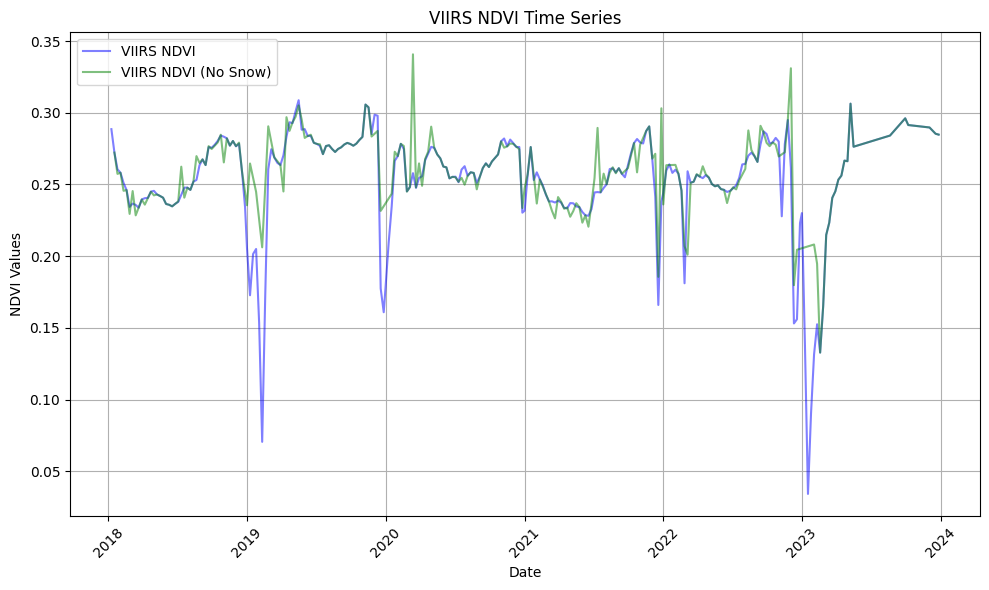

Step 3. Scale the data between 0 and 1. This is following Bischof's methods, but we are using VIIRS data which does not have a 9-year time series yet, so we will use the time period we have (2018 - present).

In [11]:
## first we will compute the 92.5th percentile for each pixel across the entire collection

percentile_ndvi = smoothed_viirs_ndvi.reduce(ee.Reducer.percentile([92.5])).rename(['NDVI'])
percentile_evi = smoothed_viirs_evi.reduce(ee.Reducer.percentile([92.5])).rename(['EVI'])

## then, define a function to scale each image by its respective percentile value
def scale_band(image, percentile_image, band_name):
    
    ## select the  band from both the image and the percentile image
    band = image.select(band_name)
    percentile_band = percentile_image.select(band_name)
    
    ## divide each pixel in the image by the corresponding pixel in the percentile image
    scaled = band.divide(percentile_band)
    
    ## ensure the scaled values are between 0 and 1
    return image.addBands(scaled.clamp(0, 1).rename(band_name + '_scaled'))

## apply the scaling function to each image in the collection
scaled_viirs_ndvi = smoothed_viirs_ndvi.map(lambda image: scale_band(image, percentile_ndvi, 'NDVI'))
scaled_viirs_evi = smoothed_viirs_evi.map(lambda image: scale_band(image, percentile_evi, 'EVI'))


Okay, now that we have done all the preprocessing, we will plot these different steps on the same figure to see how the different processing steps change the NDVI curves.

In [12]:
## first we have to get the average values for each time step in the cooridor

## this is a function so that we can get the actual data and plot it
## this function will get the average values for the region of interest for each time step

def get_time_series(image_collection, region, scale, band):
    def calculate_mean(image):
        
        ## check if the image has the 'system:time_start' property
        time_start = image.get('system:time_start')
        mean_value = image.reduceRegion(reducer=ee.Reducer.mean(), geometry=region, scale=scale)
        
        ## only proceed if the image has a valid time and mean value
        return ee.Algorithms.If(
            ee.Algorithms.IsEqual(time_start, None),
            None,  # If time_start is None, return None
            ee.Feature(None, mean_value.set('system:time_start', ee.Date(time_start).millis()))
        )

    time_series = image_collection.map(calculate_mean)
    time_series_list = time_series.getInfo()['features']

    ## extract time and values, filter out None values
    dates = []
    values = []
    for feature in time_series_list:
        date = feature['properties'].get('system:time_start')
        value = feature['properties'].get(band)

        ## skip if date or value is None
        if date is not None and value is not None:
            dates.append(date)
            values.append(value)
        

    return dates, values



## convert dates to readable format
def convert_dates(dates):
    return [datetime.fromtimestamp(date / 1000, tz=timezone.utc) for date in dates]


In [13]:
## do some troubleshooting

def get_time_series_in_batches(image_collection, region, scale, band, batch_size=50):
    """
    Retrieve time series data from a large image collection in smaller batches to avoid memory issues.
    
    Args:
    image_collection (ee.ImageCollection): The image collection.
    region (ee.Geometry): The region of interest.
    scale (int): The scale for reduceRegion.
    band (str): The band name.
    batch_size (int): The number of images to process in each batch (default: 50).
    
    Returns:
    tuple: Lists of dates and values for the entire time series.
    """
    dates = []
    values = []

    # Get the total number of images in the collection
    total_size = image_collection.size().getInfo()

    # Iterate through the collection in batches
    for i in range(0, total_size, batch_size):
        # Get a batch of images
        batch = image_collection.toList(batch_size, i)
        batch_collection = ee.ImageCollection(batch)

        # Process the batch and extract time series data
        batch_dates, batch_values = get_time_series(batch_collection, region, scale, band)
        dates.extend(batch_dates)
        values.extend(batch_values)

    return dates, values

# Apply the batch time series function to the smoothed NDVI data
viirs_ndvi_dates_smoothed, viirs_ndvi_values_smoothed = get_time_series_in_batches(
    smoothed_viirs_ndvi, reprojected_roi, scale=500, band='NDVI', batch_size=50)

# Plot the results for the full smoothed NDVI dataset
plt.plot(viirs_ndvi_dates_smoothed, viirs_ndvi_values_smoothed, label='Smoothed NDVI')
plt.xlabel('Date')
plt.ylabel('NDVI Values')
plt.legend()
plt.show()


EEException: User memory limit exceeded.

Here are the plots for NDVI:

Raw NDVI size: 258
Snow-removed NDVI size: 258
Smoothed NDVI size: 258
Properties of the Smoothed Image Collection:
{'type': 'Image', 'bands': [{'id': 'NDVI', 'data_type': {'type': 'PixelType', 'precision': 'double', 'min': -3.2768, 'max': 3.2767}, 'crs': 'EPSG:4326', 'crs_transform': [1, 0, 0, 0, 1, 0]}], 'properties': {'system:time_start': 1515456000000, 'system:index': '2018_01_09'}}


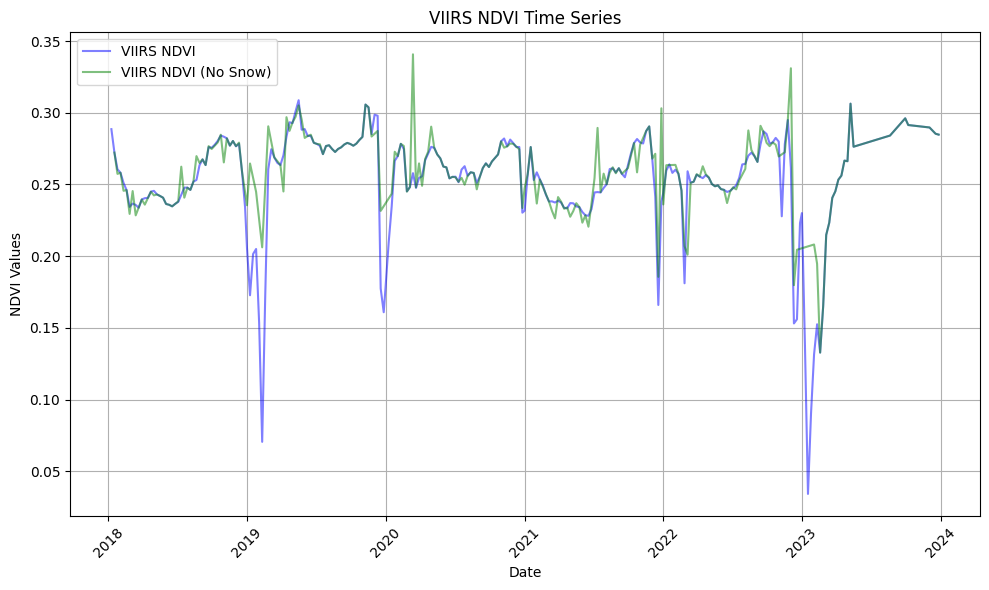

In [34]:
## some debugging stuff
## check the size of the original and smoothed collections
raw_ndvi_size = clipped_viirs_ndvi.size().getInfo()
snow_removed_size = viirs_ndvi_without_snow.size().getInfo()
smoothed_ndvi_size = smoothed_viirs_ndvi.size().getInfo()

print(f"Raw NDVI size: {raw_ndvi_size}")
print(f"Snow-removed NDVI size: {snow_removed_size}")
print(f"Smoothed NDVI size: {smoothed_ndvi_size}")

## check the properties of the smoothed images
smoothed_image_info = smoothed_viirs_ndvi.first().getInfo()
print("Properties of the Smoothed Image Collection:")
print(smoothed_image_info)


viirs_ndvi_dates, viirs_ndvi_values = get_time_series(clipped_viirs_ndvi, reprojected_roi,
                                                      scale=int(target_crs_scale.getInfo()), band='NDVI')

viirs_ndvi_dates2, viirs_ndvi_values2 = get_time_series(viirs_ndvi_without_snow, reprojected_roi,
                                                      scale=int(target_crs_scale.getInfo()), band='NDVI')

#viirs_ndvi_dates3, viirs_ndvi_values3 = get_time_series(smoothed_viirs_ndvi, reprojected_roi,
#                                                      scale=int(target_crs_scale.getInfo()), band='NDVI')

## get converted dates for each time series
viirs_ndvi_dates = convert_dates(viirs_ndvi_dates)
viirs_ndvi_dates2 = convert_dates(viirs_ndvi_dates2)
# viirs_ndvi_dates3 = convert_dates(viirs_ndvi_dates3)

## create the plot
plt.figure(figsize=(10, 6))

## plot the first time series
plt.plot(viirs_ndvi_dates, viirs_ndvi_values,
         label='VIIRS NDVI', color='blue', linestyle='-', alpha=0.5)

## plot the second time series
plt.plot(viirs_ndvi_dates2, viirs_ndvi_values2,
         label='VIIRS NDVI (No Snow)', color='green', linestyle='-', alpha=0.5)

## plot the third time series
#plt.plot(viirs_ndvi_dates3, viirs_ndvi_values3,
#         label='VIIRS NDVI (Smoothed)', color='red', linestyle='-', alpha=0.5)

## add labels and title
plt.xlabel('Date')
plt.ylabel('NDVI Values')
plt.title('VIIRS NDVI Time Series')

## rotate x-axis labels for better readability
plt.xticks(rotation=45)

## add grid and legend
plt.grid(True)
plt.legend()

## show the plot
plt.tight_layout()
plt.show()



Now we can plot the scaled data.

In [28]:

viirs_ndvi_dates_scaled, viirs_ndvi_values_scaled = get_time_series(scaled_viirs_ndvi,
                                                                    reprojected_roi,
                                                      scale=int(target_crs_scale.getInfo()),
                                                      band='NDVI')

viirs_ndvi_dates_scaled = convert_dates(viirs_ndvi_dates_scaled)

## create the plot
plt.figure(figsize=(10, 6))

## plot the first time series
plt.plot(viirs_ndvi_dates_scaled, viirs_ndvi_values_scaled,
         label='VIIRS NDVI (Scaled)', color='blue', linestyle='-', alpha=0.8)

## add labels and title
plt.xlabel('Date')
plt.ylabel('NDVI Values')
plt.title('VIIRS NDVI Time Series')

## rotate x-axis labels for better readability
plt.xticks(rotation=45)

## add grid and legend
plt.grid(True)
plt.legend()

## show the plot
plt.tight_layout()
plt.show()


EEException: User memory limit exceeded.